# Train — ResNet-18

Trains and evaluates ResNet-18 using the tuned hyperparameters from `ARCH_HYPERPARAMS["resnet18"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: off
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']
Train: 947 | Val: 229 | Test: 567


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["resnet18"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders, same as every other architecture
# here -- its own (capped) batch size and image size, per cfg.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, tuned value = 24)


## Define the model (Transfer Learning with ResNet-18)

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with ResNet-18)
# ---------------------------------------------------------
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the tuned step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[ResNet-18] Using gradient accumulation: 2 micro-batches per optimizer step (effective batch size ≈ micro_batch x 2).


[ResNet-18] Epoch   1/100 | LR: 8.42e-05 | train loss 0.8844 acc 0.650 | val loss 0.7098 acc 0.694 *


[ResNet-18] Epoch   2/100 | LR: 8.42e-05 | train loss 0.4703 acc 0.815 | val loss 0.6558 acc 0.742 *


[ResNet-18] Epoch   3/100 | LR: 8.42e-05 | train loss 0.2451 acc 0.936 | val loss 0.6872 acc 0.729


[ResNet-18] Epoch   4/100 | LR: 8.42e-05 | train loss 0.1495 acc 0.964 | val loss 0.6786 acc 0.747


...

[ResNet-18] Epoch  13/100 | LR: 8.42e-05 | train loss 0.0686 acc 0.980 | val loss 0.8497 acc 0.760


[ResNet-18] Epoch  14/100 | LR: 8.42e-05 | train loss 0.0552 acc 0.984 | val loss 0.8615 acc 0.760


[ResNet-18] Epoch  15/100 | LR: 8.42e-05 | train loss 0.0519 acc 0.985 | val loss 0.8091 acc 0.755


[ResNet-18] Epoch  16/100 | LR: 8.42e-05 | train loss 0.0932 acc 0.977 | val loss 0.9454 acc 0.734


[ResNet-18] Epoch  17/100 | LR: 8.42e-06 | train loss 0.0455 acc 0.987 | val loss 0.9281 acc 0.782

[ResNet-18] No val loss improvement for 10 epochs — stopping early at epoch 17.

[ResNet-18] Restored best checkpoint (val loss = 0.6518)


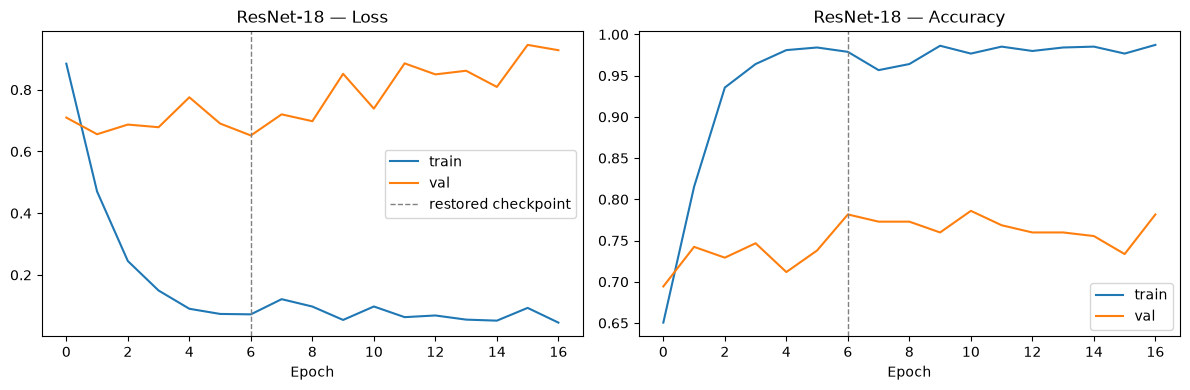

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18")

## Evaluate on the test set

[ResNet-18] Test accuracy: 0.810


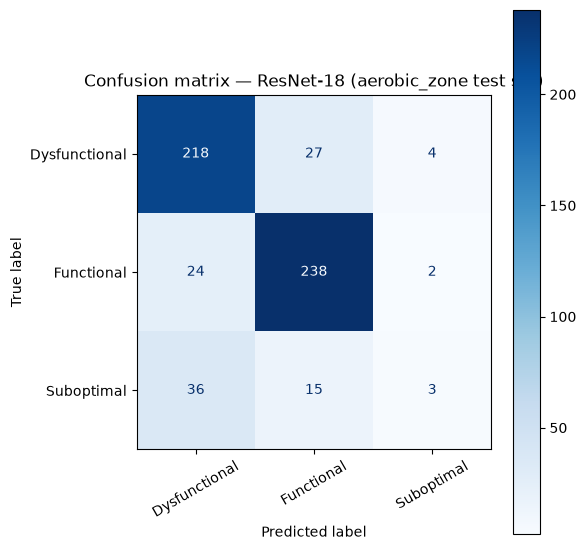

               precision    recall  f1-score   support

Dysfunctional      0.784     0.876     0.827       249
   Functional      0.850     0.902     0.875       264
   Suboptimal      0.333     0.056     0.095        54

     accuracy                          0.810       567
    macro avg      0.656     0.611     0.599       567
 weighted avg      0.772     0.810     0.780       567



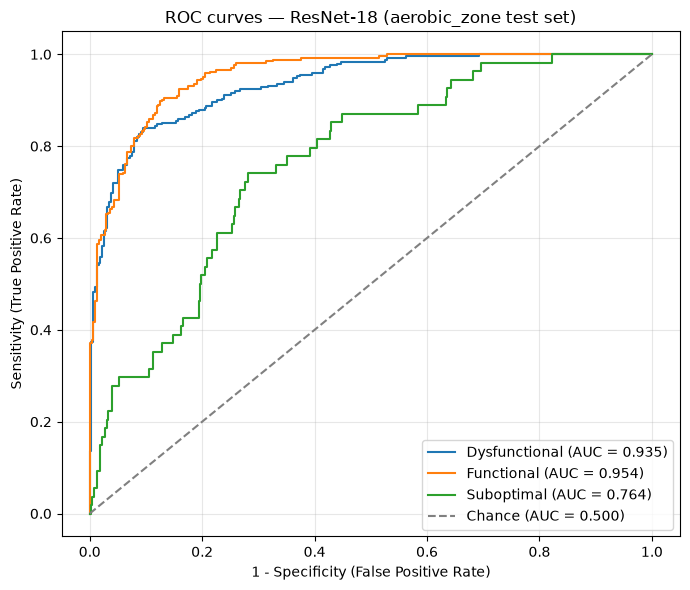

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.935
  Functional     : 0.954
  Suboptimal     : 0.764

Mean AUC (over 3/3 classes with test examples): 0.885


(np.float64(0.8095238095238095),
 {'Dysfunctional': 0.9351746609077821,
  'Functional': 0.9538453845384538,
  'Suboptimal': 0.7644935383726806})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

This is the step the results notebook depends on — it pickles the metrics/history and saves the model state dict so nothing needs to be kept in memory or re-trained.

In [6]:
save_result("ResNet-18", "resnet18")

Saved results to ../results/aerobic_zone_noaug/results_aerobic_zone_resnet18_chronological.pkl


Saved model weights to ../models/pad/aerobic_zone_resnet18_cnn.pt
